# Application 2C — bagging, decorrelation, OOB, and importance

**Question:** What does averaging trees buy us, and how can we check their internal evaluation?

Generate 2,000 rows and 20 features. The predictors $x_1,x_3,x_5,\ldots,x_{20}$ are independent
$U(-1,1)$ draws, $x_2=x_1+N(0,0.03^2)$, and $x_4\sim\operatorname{Bernoulli}(0.5)$ is independent.
$$\pi(x)=\sigma(-0.7+2.5x_1+2\mathbf1\{x_3>0.2\}),\qquad Y\mid x\sim\operatorname{Bernoulli}(\pi(x)).$$
The pair $(x_1,x_2)$ is nearly redundant; $x_4$ is binary noise and $x_5,\ldots,x_{20}$ are continuous noise.
True probabilities are not model inputs.

Use 300-tree forests to select candidate-feature count $m$ and minimum leaf size by training CV Brier.
Compare with bagging ($m=20$) and a single tree using the same chosen leaf size. Independently build
600 bootstrap trees to audit OOB masks, probability averages, and coverage. Study tree-rule similarity,
resampled predictions, and validation permutation importance.

**Protocol:** seed 17 for simulation, seed 23 for stratified 60/20/20 splits and five-fold CV.
Gini splits, unrestricted depth, explicit positive class 1, and **probability averaging** throughout.
All forest fits use `n_jobs=1`; runtime/storage comparisons use the same process and machine.
Keep settings fixed after CV. Validation diagnostics do not select a new model. Test results come last.

Run all cells with the course requirements. This notebook fits many small trees and takes longer
than A and B. See [the focused guide](02_decision_trees_and_random_forests.pdf).

## 1. Generate data and reserve the splits

Keep row indices for partition checks. No scaling is needed for these trees, and there is no learned
preprocessing before the bootstrap. This makes the manual OOB interpretation particularly direct.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.special import expit
from time import perf_counter
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import brier_score_loss

rng = np.random.default_rng(17)
n, p = 2000, 20
X = rng.uniform(-1, 1, size=(n, p))
X[:, 1] = X[:, 0] + rng.normal(0, 0.03, n)
X[:, 3] = rng.binomial(1, 0.5, n)
true_probability = expit(-0.7 + 2.5 * X[:, 0] + 2 * (X[:, 2] > 0.2))
y = rng.binomial(1, true_probability)
feature_names = [f"x{j+1}" for j in range(p)]
train_valid_ids, test_ids = train_test_split(np.arange(n), test_size=0.2, random_state=23, stratify=y)
train_ids, valid_ids = train_test_split(train_valid_ids, test_size=0.25, random_state=23,
                                        stratify=y[train_valid_ids])
assert set(train_ids).isdisjoint(valid_ids)
assert set(train_ids).isdisjoint(test_ids)
assert set(valid_ids).isdisjoint(test_ids)
X_train, y_train = X[train_ids], y[train_ids]
X_valid, y_valid = X[valid_ids], y[valid_ids]
X_test, y_test = X[test_ids], y[test_ids]
baseline_probability = y_train.mean()
print("Rows:", len(train_ids), len(valid_ids), len(test_ids))
print("Training class counts:", np.bincount(y_train))
print("Training x1/x2 correlation:", np.corrcoef(X_train[:, 0], X_train[:, 1])[0, 1])

def positive_probability(model, inputs):
    # Explicit class alignment also handles a bootstrap containing only one class.
    if 1 not in model.classes_:
        return np.zeros(len(inputs))
    positive_column = list(model.classes_).index(1)
    return model.predict_proba(inputs)[:, positive_column]

def clipped_log_loss(labels, probabilities):
    probabilities = np.clip(probabilities, 1e-12, 1 - 1e-12)
    return -np.mean(labels * np.log(probabilities) + (1 - labels) * np.log1p(-probabilities))

for one_class in [0, 1]:
    tiny = DecisionTreeClassifier(random_state=1).fit([[0], [1]], [one_class, one_class])
    np.testing.assert_allclose(positive_probability(tiny, [[0], [1]]), one_class)

Rows: 1200 400 400
Training class counts: [601 599]
Training x1/x2 correlation: 0.9985392089338259


## 2. Select feature count and leaf size with 300 trees

Search $m\in\{1,4,10,20\}$ and minimum leaf size in $\{1,5,20\}$ using identical five-fold training splits.
Each forest bootstraps its fitting rows, offers $m$ candidate columns at each split, and averages probabilities.
Choose the lowest mean CV Brier score; exact ties use loop order (smaller m, then smaller leaf size).
Do not select B from the later OOB plots: 300 is prespecified for final model comparisons.

In [2]:
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=23).split(X_train, y_train))
cv_rows = []
for m in [1, 4, 10, 20]:
    for leaf_size in [1, 5, 20]:
        scores = []
        for fold, (fit_rows, score_rows) in enumerate(folds):
            forest = RandomForestClassifier(n_estimators=300, max_features=m,
                         min_samples_leaf=leaf_size, bootstrap=True, criterion="gini",
                         random_state=31 + fold, n_jobs=1)
            forest.fit(X_train[fit_rows], y_train[fit_rows])
            probability = positive_probability(forest, X_train[score_rows])
            scores.append(brier_score_loss(y_train[score_rows], probability))
        cv_rows.append({"m": m, "leaf size": leaf_size, "CV Brier": np.mean(scores),
                        "fold SD": np.std(scores, ddof=1)})
        print("Completed:", m, "candidate features; leaf size", leaf_size)
cv_results = pd.DataFrame(cv_rows)
best = cv_results.loc[cv_results["CV Brier"].idxmin()]
best_m, best_leaf = int(best["m"]), int(best["leaf size"])
display(cv_results)
print("Frozen settings: m =", best_m, "; minimum leaf size =", best_leaf)

Completed: 1 candidate features; leaf size 1


Completed: 1 candidate features; leaf size 5


Completed: 1 candidate features; leaf size 20


Completed: 4 candidate features; leaf size 1


Completed: 4 candidate features; leaf size 5


...

Completed: 20 candidate features; leaf size 1


Completed: 20 candidate features; leaf size 5


Completed: 20 candidate features; leaf size 20


,m,leaf size,CV Brier,fold SD
0,1,1,0.176935,0.009020
1,1,5,0.182519,0.009562
2,1,20,0.196188,0.006078
3,4,1,0.160364,0.012489
4,4,5,0.158914,0.012143
5,4,20,0.162177,0.011835
6,10,1,0.160145,0.013720
7,10,5,0.157234,0.013924
8,10,20,0.156185,0.012886
9,20,1,0.161648,0.013733


Frozen settings: m = 10 ; minimum leaf size = 20


## 3. Fit the comparison models and measure tree-rule similarity

Use the CV-selected leaf size for a single tree, bagging, and all four m settings; this matching rule
was fixed before seeing results. The single tree and bagging are not separately tuned baselines.
Time the fits. Bagging here is a bootstrap forest with every feature available at each node.

Sample 400 new unlabeled diagnostic inputs from the same feature distribution. On that fixed set,
correlate the probability vectors of the first 100 trees, omitting constant vectors.
This measures similarity **across inputs**, not the fixed-input sampling correlation in the variance formula.

In [3]:
start = perf_counter()
single_tree = DecisionTreeClassifier(min_samples_leaf=best_leaf, random_state=31).fit(X_train, y_train)
single_fit_seconds = perf_counter() - start
forests = {}
fit_seconds = {}
for m in [1, 4, 10, 20]:
    model = RandomForestClassifier(n_estimators=300, max_features=m, min_samples_leaf=best_leaf,
                                    bootstrap=True, criterion="gini", random_state=31, n_jobs=1)
    start = perf_counter()
    model.fit(X_train, y_train)
    fit_seconds[m] = perf_counter() - start
    forests[m] = model
selected_forest = forests[best_m]
bagging = forests[20]

grid_rng = np.random.default_rng(59)
diagnostic_inputs = grid_rng.uniform(-1, 1, size=(400, p))
diagnostic_inputs[:, 1] = diagnostic_inputs[:, 0] + grid_rng.normal(0, 0.03, 400)
diagnostic_inputs[:, 3] = grid_rng.binomial(1, 0.5, 400)
similarity_rows = []
for m, forest in forests.items():
    vectors = np.array([positive_probability(tree, diagnostic_inputs) for tree in forest.estimators_[:100]])
    nonconstant = vectors.std(axis=1) > 0
    correlations = np.corrcoef(vectors[nonconstant])
    pairs = correlations[np.triu_indices(len(correlations), k=1)]
    similarity_rows.append({"m": m, "nonconstant trees": nonconstant.sum(),
                            "median vector correlation": np.median(pairs),
                            "10th percentile": np.quantile(pairs, 0.1),
                            "90th percentile": np.quantile(pairs, 0.9),
                            "fit seconds (300 trees)": fit_seconds[m]})
display(pd.DataFrame(similarity_rows))

,m,nonconstant trees,median vector correlation,10th percentile,90th percentile,fit seconds (300 trees)
0,1,100,0.196620,0.041538,0.446262,0.389743
1,4,100,0.583839,0.448108,0.683369,0.610800
2,10,100,0.719384,0.664157,0.770274,1.061151
3,20,100,0.741412,0.687237,0.793506,1.852926


## 4. Check OOB bookkeeping on a tiny example

For four rows, use bootstrap lists `[0,0,1,2]`, `[1,1,2,3]`, and `[0,2,2,3]`.
A row contributes to its OOB average only if its index is absent from that list.
Using the supplied numerical prediction vectors, expected OOB values are 3, 6, undefined, and 8.
Coverage is 3/4. The same bookkeeping works for regression values or positive probabilities.

In [4]:
small_draws = [np.array([0, 0, 1, 2]), np.array([1, 1, 2, 3]), np.array([0, 2, 2, 3])]
small_predictions = np.array([[2, 4, 6, 8], [3, 5, 7, 9], [4, 6, 8, 10]], dtype=float)
small_sum = np.zeros(4)
small_count = np.zeros(4, dtype=int)
for draws, predictions in zip(small_draws, small_predictions):
    is_oob = np.bincount(draws, minlength=4) == 0
    small_sum[is_oob] += predictions[is_oob]
    small_count[is_oob] += 1
covered = small_count > 0
small_oob = np.full(4, np.nan)
small_oob[covered] = small_sum[covered] / small_count[covered]
np.testing.assert_allclose(small_oob, [3, 6, np.nan, 8], equal_nan=True)
assert covered.mean() == 0.75
display(pd.DataFrame({"row": np.arange(4), "OOB trees": small_count, "OOB prediction": small_oob}))

,row,OOB trees,OOB prediction
0,0,1,3.0
1,1,1,6.0
2,2,0,NaN
3,3,1,8.0


## 5. Independently implement bootstrap aggregation and OOB curves

Fit 600 trees with `max_features=20` (manual bagging), the selected leaf size, and explicit bootstrap lists.
Retain every list, OOB mask, and training prediction vector. At prefixes B = 10, 30, 100, 300, 600,
report Brier only on rows with OOB predictions, along with coverage and OOB counts.

Compare mean counts with $Bq_n$, where $q_n=(1-1/n)^n$. Independently recompute all final row averages
from the stored matrix and check masks against membership in the lists. Random streams differ from
`RandomForestClassifier`, so exact equality with its trees is not expected.

Bootstrap multiplicities are passed as sample weights, matching the reference forest's
representation. Zero-weight rows do not enter the fitted splits or leaf averages. Minimum leaf
size counts distinct included rows in this representation, while their weights retain repeated draws.

,B,OOB Brier,coverage,mean OOB count,expected mean count,minimum count,maximum count
0,10,0.168660,0.990833,3.701667,3.677261,0,8
1,30,0.160113,1.000000,11.090000,11.031783,3,19
2,100,0.157260,1.000000,36.789167,36.772610,22,55
3,300,0.157443,1.000000,110.213333,110.317831,86,135
4,600,0.157494,1.000000,220.389167,220.635663,185,261


OOB masks, class alignment, and all row averages verified.
OOB count percentiles: [185. 205. 221. 236. 261.]
Manual 600-tree bagging: OOB Brier 0.15749443581918154 ; validation Brier 0.15586852538456042


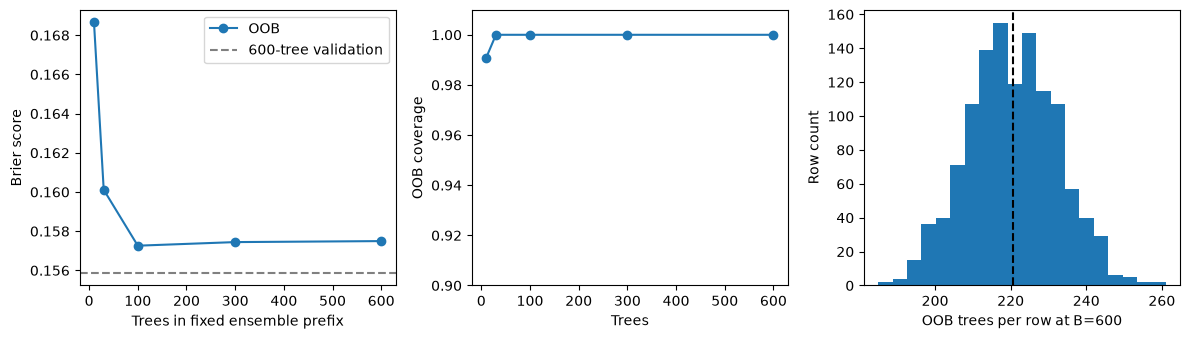

In [5]:
bootstrap_rng = np.random.default_rng(71)
n_train = len(y_train)
manual_trees = []
bootstrap_lists = []
oob_masks = []
training_predictions = []
oob_sum = np.zeros(n_train)
oob_count = np.zeros(n_train, dtype=int)
oob_rows = []
q_n = (1 - 1 / n_train) ** n_train
for b in range(600):
    draws = bootstrap_rng.integers(0, n_train, n_train)
    tree = DecisionTreeClassifier(max_features=p, min_samples_leaf=best_leaf, random_state=1000 + b)
    multiplicity = np.bincount(draws, minlength=n_train)
    tree.fit(X_train, y_train, sample_weight=multiplicity)
    is_oob = multiplicity == 0
    probability = positive_probability(tree, X_train)
    manual_trees.append(tree)
    bootstrap_lists.append(draws)
    oob_masks.append(is_oob)
    training_predictions.append(probability)
    oob_sum[is_oob] += probability[is_oob]
    oob_count[is_oob] += 1
    B = b + 1
    if B in [10, 30, 100, 300, 600]:
        covered = oob_count > 0
        current_oob = oob_sum[covered] / oob_count[covered]
        oob_rows.append({"B": B, "OOB Brier": brier_score_loss(y_train[covered], current_oob),
                         "coverage": covered.mean(), "mean OOB count": oob_count.mean(),
                         "expected mean count": B * q_n, "minimum count": oob_count.min(),
                         "maximum count": oob_count.max()})
mask_matrix = np.array(oob_masks)
prediction_matrix = np.array(training_predictions)
assert (oob_count > 0).all()
direct_oob = np.sum(prediction_matrix * mask_matrix, axis=0) / mask_matrix.sum(axis=0)
manual_oob = oob_sum / oob_count
np.testing.assert_allclose(direct_oob, manual_oob)
np.testing.assert_array_equal(mask_matrix.sum(axis=0), oob_count)
for row in [0, 1, 17, 100, n_train - 1]:
    direct_mask = np.array([row not in draws for draws in bootstrap_lists])
    np.testing.assert_array_equal(direct_mask, mask_matrix[:, row])
    np.testing.assert_allclose(prediction_matrix[direct_mask, row].mean(), manual_oob[row])
oob_results = pd.DataFrame(oob_rows)
display(oob_results)
print("OOB masks, class alignment, and all row averages verified.")
print("OOB count percentiles:", np.percentile(oob_count, [0, 10, 50, 90, 100]))

manual_valid = np.mean([positive_probability(tree, X_valid) for tree in manual_trees], axis=0)
manual_valid_brier = brier_score_loss(y_valid, manual_valid)
print("Manual 600-tree bagging: OOB Brier", brier_score_loss(y_train, manual_oob),
      "; validation Brier", manual_valid_brier)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].plot(oob_results["B"], oob_results["OOB Brier"], "o-", label="OOB")
axes[0].axhline(manual_valid_brier, color="gray", linestyle="--", label="600-tree validation")
axes[0].set(xlabel="Trees in fixed ensemble prefix", ylabel="Brier score")
axes[0].legend()
axes[1].plot(oob_results["B"], oob_results["coverage"], "o-")
axes[1].set(xlabel="Trees", ylabel="OOB coverage", ylim=(0.9, 1.01))
axes[2].hist(oob_count, bins=20)
axes[2].axvline(600 * q_n, color="black", linestyle="--")
axes[2].set(xlabel="OOB trees per row at B=600", ylabel="Row count")
plt.tight_layout()
plt.show()

## 6. Separately study fixed-input prediction variability

Resample the training data 10 times. Fit a single tree and a full 300-tree forest on each resample,
keeping the selected m/leaf setting. Compare probability variability at three prespecified inputs;
unlisted coordinates are zero. The redundant feature remains equal to x1 and binary x4 remains zero.
These are descriptive bootstrap diagnostics, not precise variance estimates or independent test sets.

In [6]:
fixed_inputs = np.zeros((3, p))
fixed_inputs[:, 0] = [-0.7, 0.0, 0.7]
fixed_inputs[:, 1] = fixed_inputs[:, 0]
fixed_inputs[:, 2] = [-0.5, 0.2, 0.7]
resample_rng = np.random.default_rng(83)
stability_rows = []
for repeat in range(10):
    rows = resample_rng.integers(0, n_train, n_train)
    tree = DecisionTreeClassifier(min_samples_leaf=best_leaf, random_state=2000 + repeat)
    forest = RandomForestClassifier(n_estimators=300, max_features=best_m,
                min_samples_leaf=best_leaf, bootstrap=True, random_state=2000 + repeat, n_jobs=1)
    for name, model in [("Single tree", tree), ("Selected forest", forest)]:
        model.fit(X_train[rows], y_train[rows])
        predictions = positive_probability(model, fixed_inputs)
        for profile, probability in enumerate(predictions):
            stability_rows.append({"profile": profile, "model": name, "probability": probability})
display(pd.DataFrame(fixed_inputs[:, :4], columns=feature_names[:4]))
stability_results = pd.DataFrame(stability_rows)
display(stability_results.groupby(["profile", "model"])["probability"].agg(["mean", "std"]).round(4))

,x1,x2,x3,x4
0,-0.7,-0.7,-0.5,0.0
1,0.0,0.0,0.2,0.0
2,0.7,0.7,0.7,0.0


mean     std
profile model                          
0       Selected forest  0.0171  0.0086
        Single tree      0.0132  0.0416
1       Selected forest  0.3712  0.1309
        Single tree      0.2981  0.3544
2       Selected forest  0.9821  0.0068
        Single tree      1.0000  0.0000

## 7. Compare training MDI and validation permutation importance

For the frozen selected forest, record training mean decrease in impurity (MDI).
On validation only, shuffle each feature 10 times and measure the increase in Brier loss.
Restore the original matrix for each shuffle; never refit the model. Positive change means the shuffle hurts.
Use a shared row permutation for a joint shuffle of (x1,x2), preserving their near-equality.

Interpret the measures on their own scales. A noise column can receive training split credit.
Redundant columns can share useful information, and an individual shuffle creates unusual feature combinations.
Permutation SD measures shuffle variability, not population uncertainty. Do not remove features or retune
from these diagnostics within this experiment.

,role,training MDI,Brier increase,shuffle SD
feature,,,,
x1,signal,0.305876,0.031554,0.002676
x2,redundant,0.283929,0.026835,0.005182
x3,signal,0.211423,0.051160,0.008014
x4,binary noise,0.001709,0.000213,0.000081
x5,continuous noise,0.013781,0.000370,0.000752
x6,continuous noise,0.015425,0.000780,0.000477
x7,continuous noise,0.011607,-0.000022,0.000312
x8,continuous noise,0.007669,0.000150,0.000120
x9,continuous noise,0.013668,-0.000364,0.000600


Joint x1/x2 permutation: mean Brier increase 0.13138736428915054 ; shuffle SD 0.010505096102352757


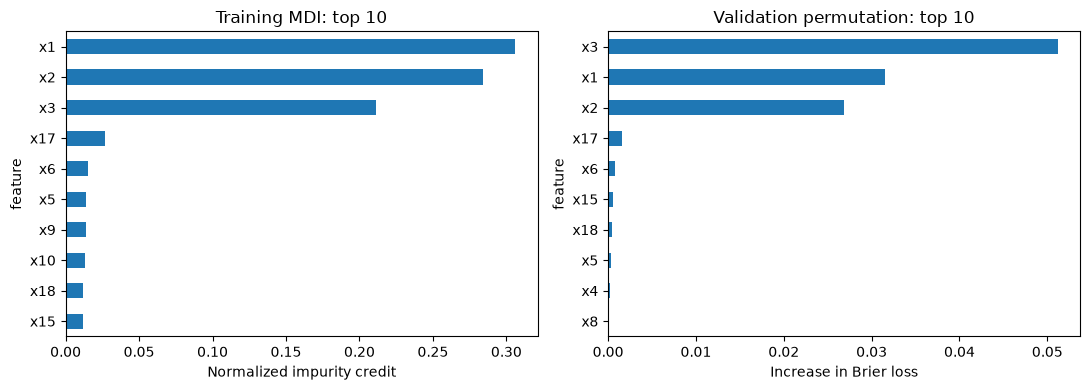

In [7]:
validation_probability = positive_probability(selected_forest, X_valid)
base_brier = brier_score_loss(y_valid, validation_probability)
permutation_rng = np.random.default_rng(97)
importance_rows = []
for j, feature in enumerate(feature_names):
    changes = []
    for repeat in range(10):
        shuffled = X_valid.copy()
        shuffled[:, j] = shuffled[permutation_rng.permutation(len(X_valid)), j]
        loss = brier_score_loss(y_valid, positive_probability(selected_forest, shuffled))
        changes.append(loss - base_brier)
    role = "signal" if j in [0, 2] else "redundant" if j == 1 else "binary noise" if j == 3 else "continuous noise"
    importance_rows.append({"feature": feature, "role": role,
                            "training MDI": selected_forest.feature_importances_[j],
                            "Brier increase": np.mean(changes), "shuffle SD": np.std(changes, ddof=1)})
importance_results = pd.DataFrame(importance_rows).set_index("feature")
group_changes = []
for repeat in range(10):
    permutation = permutation_rng.permutation(len(X_valid))
    shuffled = X_valid.copy()
    shuffled[:, [0, 1]] = X_valid[permutation][:, [0, 1]]
    loss = brier_score_loss(y_valid, positive_probability(selected_forest, shuffled))
    group_changes.append(loss - base_brier)
display(importance_results)
print("Joint x1/x2 permutation: mean Brier increase", np.mean(group_changes),
      "; shuffle SD", np.std(group_changes, ddof=1))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
importance_results["training MDI"].nlargest(10).sort_values().plot.barh(ax=axes[0])
importance_results["Brier increase"].nlargest(10).sort_values().plot.barh(ax=axes[1])
axes[0].set(title="Training MDI: top 10", xlabel="Normalized impurity credit")
axes[1].set(title="Validation permutation: top 10", xlabel="Increase in Brier loss")
plt.tight_layout()
plt.show()

## 8. Final test comparison

Evaluate the prevalence baseline, single tree, 300-tree bagging, and selected 300-tree forest.
The manual 600-tree ensemble is a separate OOB diagnostic and does not replace the prespecified bagging baseline.
Report Brier and **clipped** log loss using the same $10^{-12}$ clipping for all candidates.

Report trees, total nodes (a storage proxy), original training-fit time, and median probability-prediction
time for the same test feature batch over 10 repeats. Prediction timing repeats do not change the fits
or use test targets for selection. If CV chooses m=20, bagging and the selected forest are the same fitted object.

In [8]:
comparison_models = {"Single tree": single_tree, "Bagging (m=20)": bagging,
                     "Selected forest": selected_forest}
original_fit_times = {"Single tree": single_fit_seconds, "Bagging (m=20)": fit_seconds[20],
                      "Selected forest": fit_seconds[best_m]}
p_baseline = np.full(len(y_test), baseline_probability)
test_rows = [{"model": "Prevalence baseline", "Brier": brier_score_loss(y_test, p_baseline),
              "clipped log loss": clipped_log_loss(y_test, p_baseline),
              "trees": 0, "total nodes": 0, "fit seconds": None, "batch predict ms": None}]
for name, model in comparison_models.items():
    probability = positive_probability(model, X_test)
    trees = [model] if name == "Single tree" else model.estimators_
    timings = []
    for repeat in range(10):
        start = perf_counter()
        positive_probability(model, X_test)
        timings.append(1000 * (perf_counter() - start))
    test_rows.append({"model": name, "Brier": brier_score_loss(y_test, probability),
                      "clipped log loss": clipped_log_loss(y_test, probability),
                      "trees": len(trees), "total nodes": sum(tree.tree_.node_count for tree in trees),
                      "fit seconds": original_fit_times[name], "batch predict ms": np.median(timings)})
test_results = pd.DataFrame(test_rows).set_index("model")
display(test_results.round(5))

,Brier,clipped log loss,trees,total nodes,fit seconds,batch predict ms
model,,,,,,
Prevalence baseline,0.25000,0.69315,0,0,NaN,NaN
Single tree,0.20461,1.71822,1,75,0.01039,0.11481
Bagging (m=20),0.18481,0.55925,300,15000,1.85293,23.07997
Selected forest,0.18281,0.54847,300,15656,1.06115,21.79354


## Interpret the results

- Does reducing m always improve CV Brier? Feature randomization balances tree diversity against split strength.
- Why is a row's OOB average different from averaging all trees at that row? What happens if its OOB count is zero?
- Compare internal OOB and validation Brier for the same manual ensemble; they need not agree exactly.
- Distinguish prediction-vector similarity across inputs from variability of predictions at one fixed input.
- Compare x1 and x2 individually and jointly. Why is feature importance not a list of causal effects?
- Are continuous noise columns credited more MDI than binary noise x4, and does validation support that credit?
- The labels are stochastic. An ensemble may improve probabilities without eliminating every classification error.

**In the saved run:** CV chooses m=10 and minimum leaf size 20. OOB coverage rises
from about 99.1% at 10 trees to 100% at 30. At 600 trees, manual bagging has OOB Brier
about 0.1575 and validation Brier about 0.1559. Jointly permuting x1/x2 increases
validation Brier by about 0.131, versus about 0.032 and 0.027 individually. This shows
why separate importance scores do not simply add for redundant inputs. Final test Brier
is about 0.1828 for the selected forest, 0.1848 for bagging, 0.2046 for one tree, and
0.2500 for prevalence alone; this one test sample does not establish a universal ranking.